In [ ]:
# Install loompy
!pip install scanpy
# Navigate into the SpaGE directory
%cd SpaGE

Cloning into 'SpaGE'...
remote: Enumerating objects: 347, done.
remote: Counting objects: 100% (252/252), done.
remote: Compressing objects: 100% (95/95), done.
remote: Total 347 (delta 149), reused 244 (delta 144), pack-reused 95 (from 1)
Receiving objects: 100% (347/347), 2.59 MiB | 714.00 KiB/s, done.
Resolving deltas: 100% (187/187), done.
/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation/SpaGE


### **1. Setting Up**

In [16]:
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
from anndata import AnnData
import pathlib
import matplotlib.pyplot as plt
import matplotlib as mpl
import skimage
import seaborn as sns
import tangram as tg
from sklearn.metrics import auc
from skimage.metrics import structural_similarity as ssim
from scipy import sparse
import scipy.stats as st
import sys
sys.path.append('./SpaGE/SpaGE')  # Points to the folder containing main.py
from main import SpaGE

sc.logging.print_header()
print(f"squidpy=={sq.__version__}")


%load_ext autoreload
%autoreload 2
%matplotlib inline



scanpy==1.9.8 anndata==0.9.2 umap==0.5.7 numpy==1.22.4 scipy==1.10.1 pandas==2.0.3 scikit-learn==1.3.2 statsmodels==0.14.1 igraph==0.11.8 pynndescent==0.5.13
squidpy==1.2.3
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### **2. Loading Datasets and Exploration**

In [2]:
# import os
# print(os.getcwd())
# os.chdir('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation')

adata_sc = sc.read('gene_data/ageing_rna_20250114.h5ad')
print(adata_sc)

adata_st = sc.read('gene_data/ag02reg00_rawcounts.h5ad')
print(adata_st)

AnnData object with n_obs × n_vars = 173199 × 19957
    obs: 'id_barcode', 'scDblFinder_score', 'scDblFinder_class', 'celltype', 'sample', 'barcode', 'id_barcode.1', 'cell_id', 'class_label', 'class_name', 'class_bootstrapping_probability', 'subclass_label', 'subclass_name', 'subclass_bootstrapping_probability', 'supertype_label', 'supertype_name', 'supertype_bootstrapping_probability', 'cluster_label', 'cluster_name', 'cluster_alias', 'cluster_bootstrapping_probability', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'leverage.score', 'sketch_snn_res.2', 'seurat_clusters', 'celltype.full', 'celltype.full.score', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'Name', 'Sex', 'Line', 'DOB', 'DOD', 'age_days', 'age_months', 'Sample #'
    var: 'Unnamed: 0'
AnnData object with n_obs × n_vars = 40576 × 500
    obs: 'EntityID', 'fov', 'volume', 'center_x', 'center_y', 'min_x', 'min_y', 'max_x', 'max_y', 'anisotropy', 'transcript_count', 'perimeter_area_ratio', 'solidity', 'cell_id', 'class_la

### **3. Data Pre-Processing and Training Gene Selection**

1. **Normalise** gene data raw counts across both datasets

In [3]:
# Normalise the single-cell data (because different cells are sequenced at different depths)
sc.pp.normalize_total(adata_sc, target_sum=1e4)
sc.pp.log1p(adata_sc)

# Normalise the spatial data (because different cells are sequenced at different depths)
sc.pp.normalize_total(adata_st, target_sum=1e4)
sc.pp.log1p(adata_st)

# Removes the "class" or "subclass" groups that have more than one sample
# This means statistics cannot be performed on this group
grouping_strategy = "subclass_name"
valid_classes = adata_sc.obs[grouping_strategy].value_counts()[lambda x: x > 1].index
adata_sc = adata_sc[adata_sc.obs[grouping_strategy].isin(valid_classes)]

In [ ]:
np_adata_sc = adata_sc.X.toarray()

# Convert single cell and spatial data into Pandas DataFrames
adata_sc_df = pd.DataFrame(np_adata_sc, columns=adata_sc.var_names)
adata_st_df = pd.DataFrame(adata_st.X, columns=adata_st.var_names)

<class 'numpy.ndarray'>


### **4. Find alignment and Validate SpaGE using LOO Cross-Validation**

In [7]:
shared_genes = list(adata_st_df.columns.intersection(adata_sc_df.columns))

# Filter both DataFrames to only shared genes
adata_sc_df = adata_sc_df[shared_genes]
adata_st_df = adata_st_df[shared_genes]

In [9]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((np.array(y_true) - np.array(y_pred)) ** 2))

KeyboardInterrupt: 

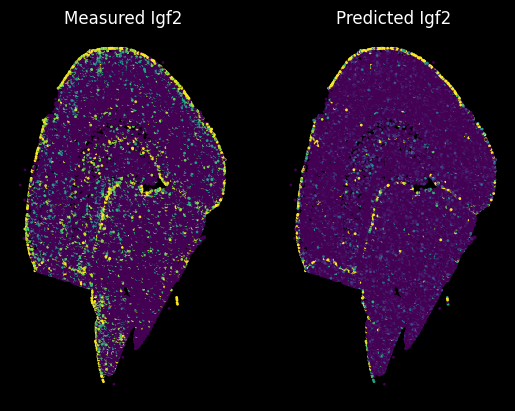

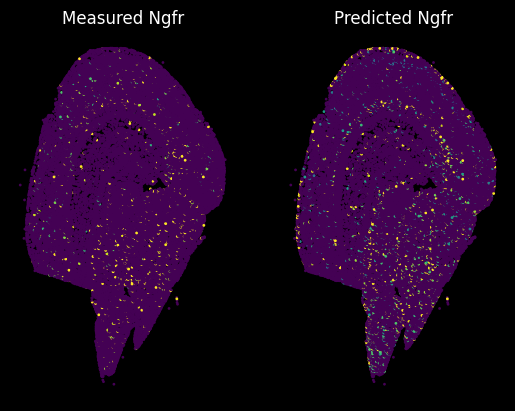

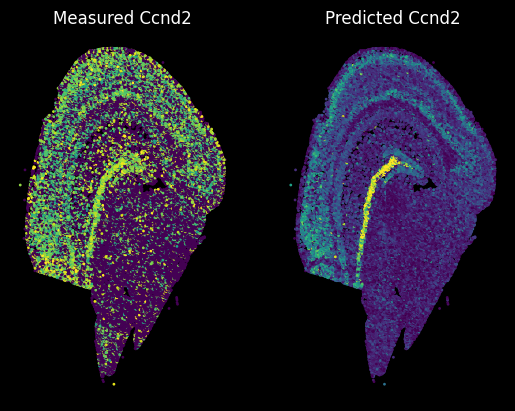

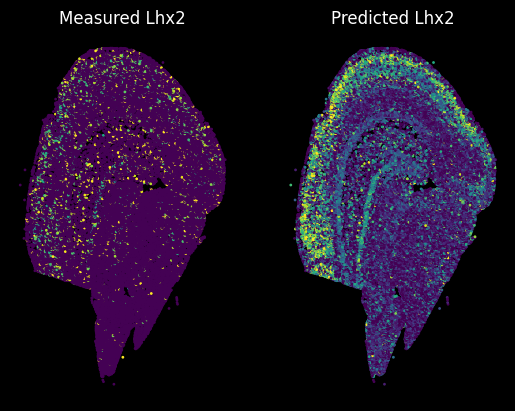

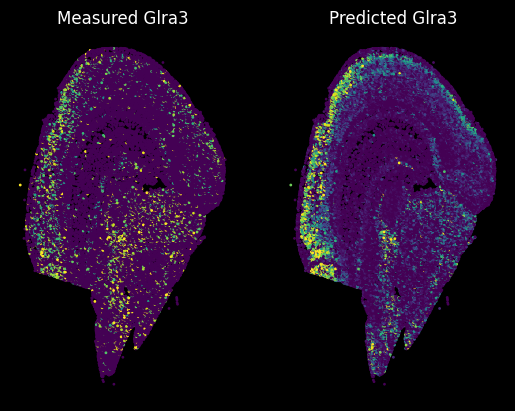

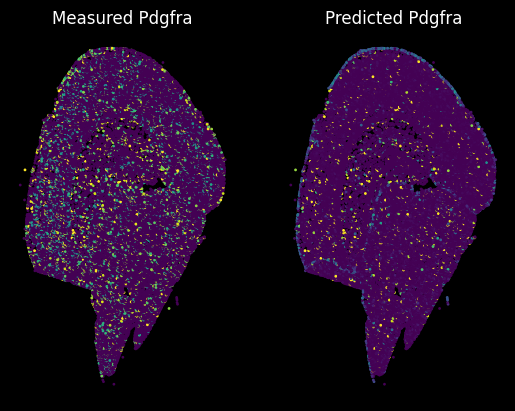

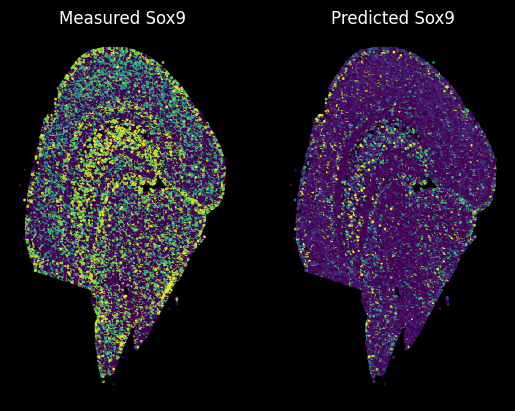

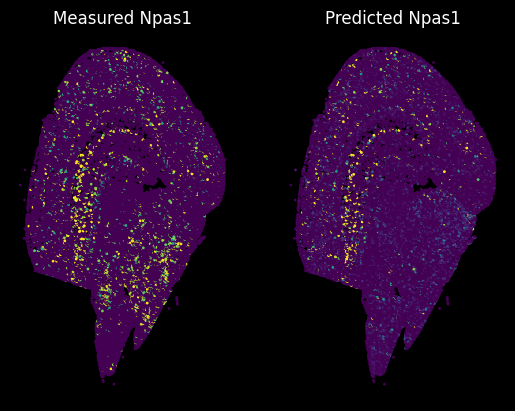

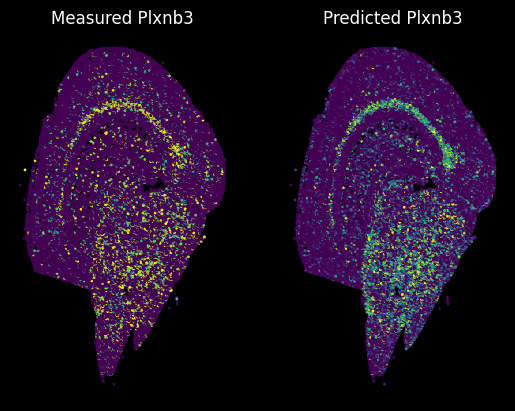

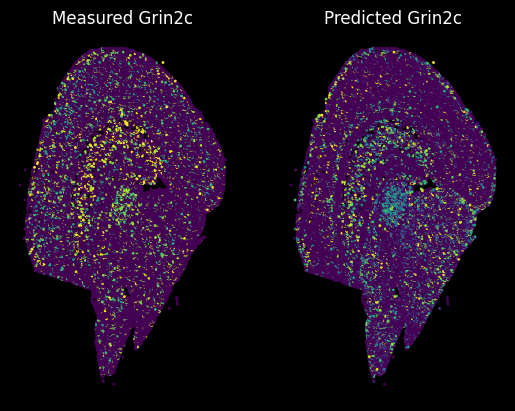

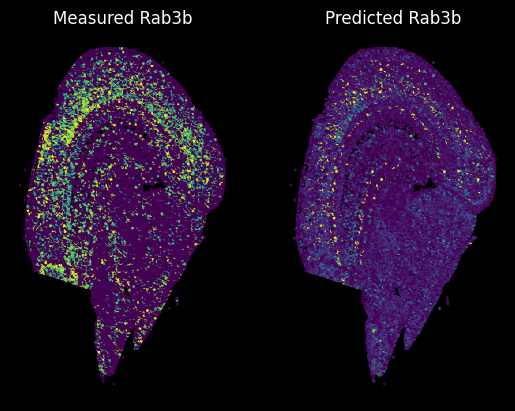

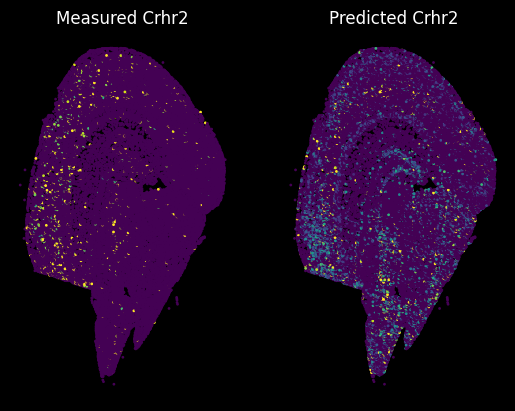

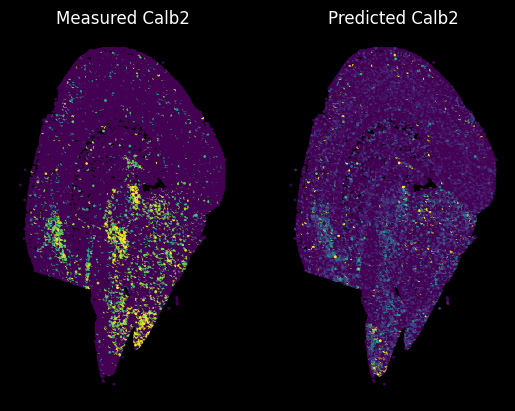

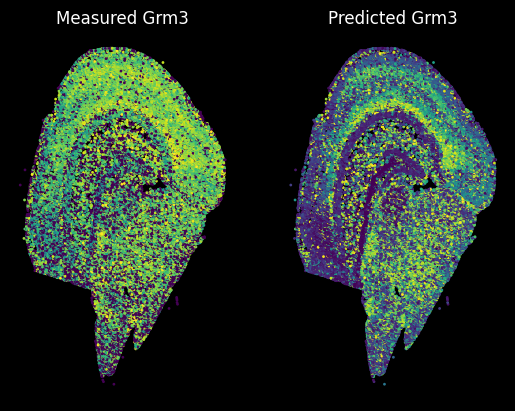

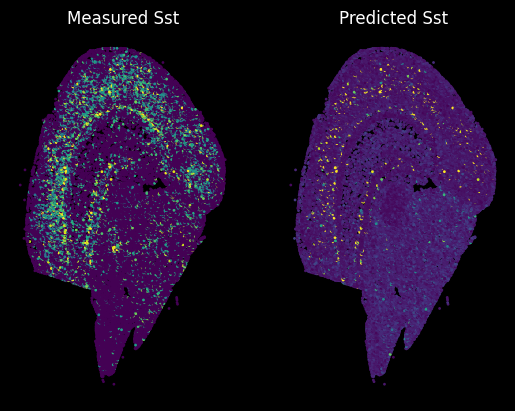

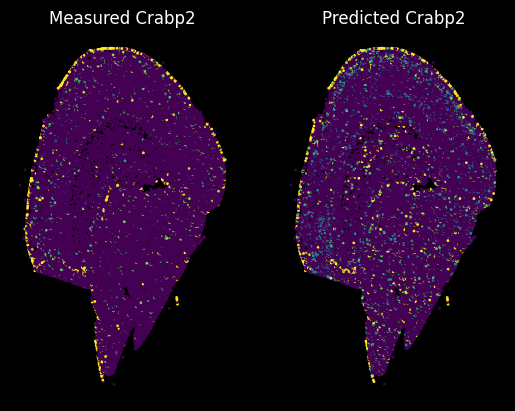

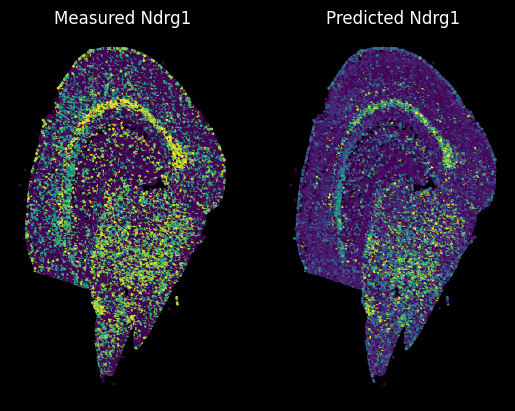

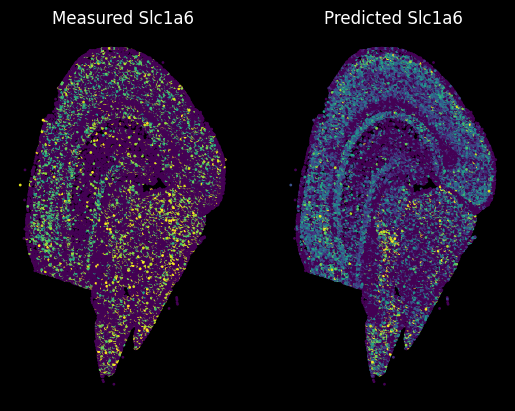

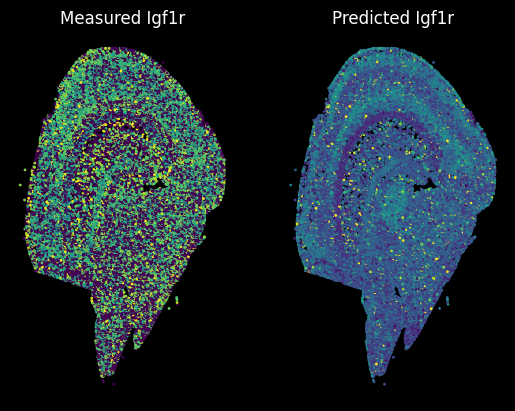

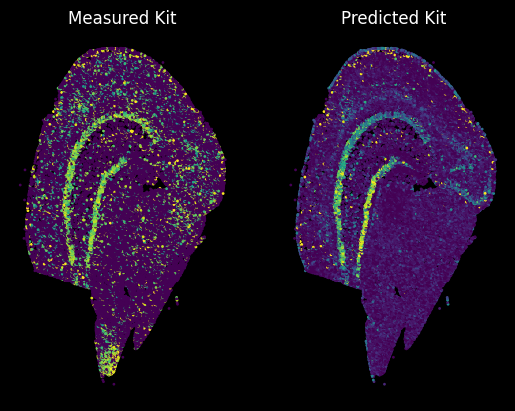

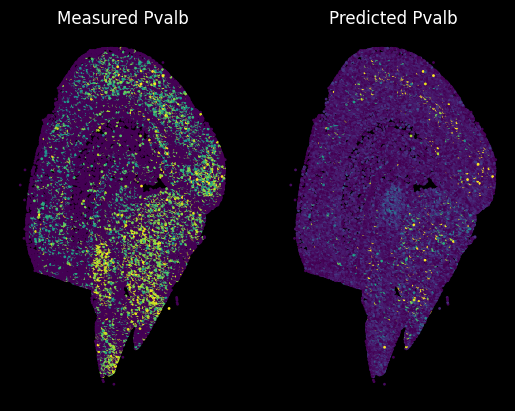

In [32]:
Gene_set = shared_genes

# Metric storage
metrics_df = pd.DataFrame(columns=['Pearson', 'Spearman', 'Cosine', 'RMSE'], index=Gene_set)


plt.style.use('dark_background')

for i in Gene_set:
  Imp_Genes = SpaGE(adata_st_df.drop(i,axis=1),adata_sc_df, n_pv=30, genes_to_predict = [i])
  metrics_df.loc[i, 'Pearson'] = st.pearsonr(adata_st_df[i], Imp_Genes[i])[0]
  metrics_df.loc[i, 'Spearman'] = st.spearmanr(adata_st_df[i], Imp_Genes[i])[0]
  metrics_df.loc[i, 'RMSE'] = rmse(adata_st_df[i], Imp_Genes[i])

  v1 = adata_st_df[i].values
  v2 = Imp_Genes[i].values
  if np.linalg.norm(v1) == 0 or np.linalg.norm(v2) == 0:
      metrics_df.loc[i, 'Cosine'] = np.nan
  else:
      metrics_df.loc[i, 'Cosine'] = (v1 @ v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))

  fig, (ax1, ax2) = plt.subplots(1, 2)
  ax1.axis('off')
  cmap = adata_st_df[i]
  cmap[cmap > np.percentile(cmap,99)] = np.percentile(cmap,99)        # Sets a maximum values for the 99th percentile
  ax1.scatter(adata_st.obs['center_x'],adata_st.obs['center_y'],s=1,c=cmap)
  ax1.set_title('Measured ' + i, fontsize = 12)
  ax1.set_ylabel(i)

  ax2.axis('off')
  cmap = Imp_Genes[i]
  cmap[cmap > np.percentile(cmap,99)] = np.percentile(cmap,99)
  ax2.scatter(adata_st.obs['center_x'],adata_st.obs['center_y'],s=1,c=cmap)
  ax2.set_title('Predicted ' + i, fontsize = 12)

In [ ]:
metrics_df.to_csv('SpaGE_metrics.csv')

In [30]:

print(f"Pearson Correlations: \n{metrics_df['Pearson']}")
print(f"Spearman Correlations: \n{metrics_df['Spearman']}")
print(f"Cosine Similarity: \n{metrics_df['Cosine']}")
print(f"RMSE: \n{metrics_df['RMSE']}")

Pearson Correlations: 
Igf2    0.366715
Name: Pearson, dtype: object
Spearman Correlations: 
Igf2    0.159086
Name: Spearman, dtype: object
Cosine Similarity: 
Igf2    0.420329
Name: Cosine, dtype: object
RMSE: 
Igf2    1.627635
Name: RMSE, dtype: object


In [22]:
print(adata_st_df[i])
print(Imp_Genes[i])

0        0.000000
1        5.343928
2        0.000000
3        4.635125
4        0.000000
           ...   
40571    4.776153
40572    0.000000
40573    0.000000
40574    0.000000
40575    4.051736
Name: Ccnd2, Length: 40576, dtype: float32
0        0.028643
1        0.330025
2        0.000000
3        0.035668
4        0.277190
           ...   
40571    0.000000
40572    0.049540
40573    0.071204
40574    0.035550
40575    0.033340
Name: Ccnd2, Length: 40576, dtype: float64
